Registered users: highest mean among displayed bins at 33°C (n=538 hours in bin)
Casual users: highest mean among displayed bins at 33°C (n=538 hours in bin)


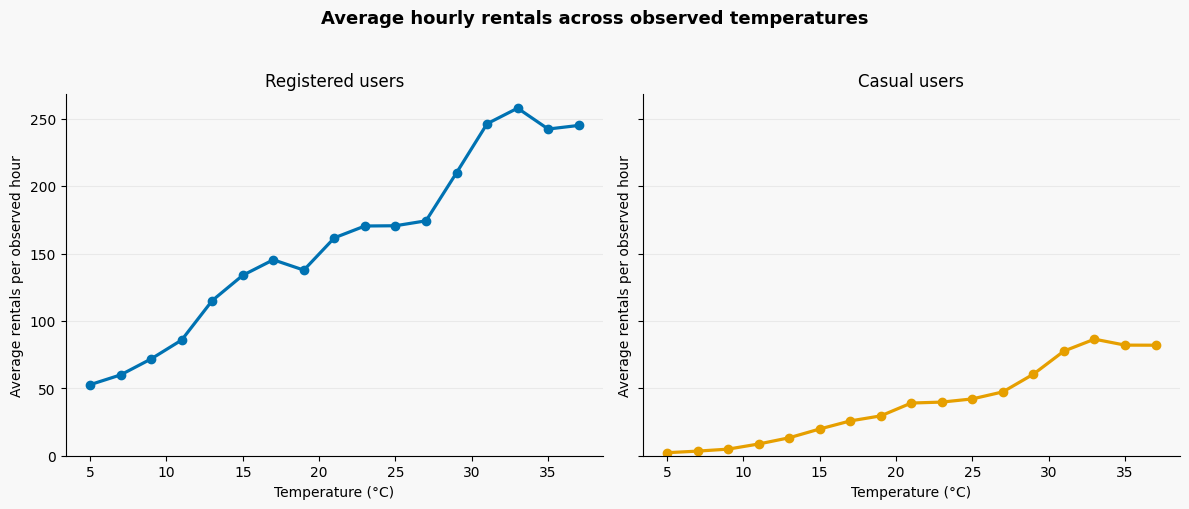

,temp_bin,n,registered,casual
2,"[4, 6)",265,52.7,2.2
3,"[6, 8)",385,60.0,3.4
4,"[8, 10)",1297,71.8,4.9
5,"[10, 12)",860,85.8,8.7
6,"[12, 14)",1897,115.1,13.3
7,"[14, 16)",1043,133.9,19.8
8,"[16, 18)",1162,145.4,25.8
9,"[18, 20)",1354,137.7,29.6
10,"[20, 22)",1087,161.7,39.1
11,"[22, 24)",1453,170.4,39.8


In [1]:
# Temperatura e noleggi

# Importiamo le librerie e impostiamo lo stile dei grafici.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

MUTED = '#647280'
REGISTERED = '#0072B2'
CASUAL = '#E69F00'
plt.rcParams['figure.facecolor'] = '#F8F8F8'
plt.rcParams['axes.facecolor'] = '#F8F8F8'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Apriamo i dati orari già puliti.
hour=pd.read_csv('../data/processed/bike_hour_clean.csv')
Path('../output/figures').mkdir(parents=True,exist_ok=True)

# Riportiamo la temperatura normalizzata in gradi Celsius.
hour['temp_c']=hour['temp']*41

# Raggruppiamo le temperature in intervalli di 2 °C.
hour['temp_bin']=pd.cut(hour['temp_c'],bins=np.arange(0,44,2),right=False)

# Calcoliamo quante ore e quanti noleggi medi ci sono in ogni intervallo.
summary=(hour.groupby('temp_bin',observed=True)
         .agg(n=('cnt','size'),registered=('registered','mean'),
              casual=('casual','mean')).reset_index())
summary['temp_mid']=summary['temp_bin'].apply(lambda x:x.mid).astype(float)

# Manteniamo solo intervalli con almeno 40 osservazioni.
used=summary.loc[summary['n']>=40].copy()

# Disegniamo due grafici con la stessa scala verticale.
fig,axes=plt.subplots(1,2,figsize=(12,4.9),sharey=True)

# Disegniamo l’andamento dei noleggi al variare della temperatura.
for ax,key,color,title in zip(axes,['registered','casual'],
                              [REGISTERED,CASUAL],['Registered users','Casual users']):
    ax.plot(used['temp_mid'],used[key],color=color,marker='o',linewidth=2.3)
    # Individuiamo il massimo soltanto per la verifica numerica, non per segnare un valore “ottimale”.
    highest = used.loc[used[key].idxmax()]
    ax.set(title=title,xlabel='Temperature (°C)',ylabel='Average rentals per observed hour')
    ax.set_ylim(bottom=0);ax.grid(axis='y', alpha=0.2); ax.set_axisbelow(True)
    print(f'{title}: highest mean among displayed bins at {highest["temp_mid"]:.0f}°C '
          f'(n={int(highest["n"])} hours in bin)')
fig.suptitle('Average hourly rentals across observed temperatures',
             fontsize=13,fontweight='bold',y=1.03)
fig.tight_layout()
fig.savefig('../output/figures/RQ4_temperature.png',dpi=200,bbox_inches='tight')
plt.show()

# Mostriamo la tabella con le numerosità per controllare i risultati.
display(used[['temp_bin','n','registered','casual']].round(1))